# 03 · Калибровка внутри CV и экспорт benchmark-моделей

## tl;dr

Калибровка фиксированной температурой обучается на OOF текущей fit-части. Внешние группы в неё не входят. Порог argmax фиксирован; маленькая прежняя validation больше не выбирает несколько политик. Финальные модели fit на всей UCI и не имеют отдельного независимого test-score.

Исправленная процедура: mean group-balanced Macro-F1 **0.855**, recall suspect **70.5%**, recall pathologic **82.6%**. Это средние метрики трёх повторов, не точность финального full-data fit.


## Context & Methods
### Key Assumptions
Фиксированная temperature-калибровка fit на OOF текущей внешней fit-части. Выбор гиперпараметров внутри неё уже использовал эти метки; внешний фолд оценивает всю процедуру. Нет выбора калибратора и threshold по прежней маленькой validation. Усреднение в UCI v3 не вводилось: вывод о бесполезности любого ансамбля из старого сравнения не делается.


In [3]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
REVIEW=ROOT/'research/reviews/ctg_20261017'
UCI=ROOT/'research/experiments/ctg_uci/reviewed_v3'
JNU=ROOT/'research/experiments/jnu_ctg/reviewed_v2'
FIGURES=REVIEW/'figures';FIGURES.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',170)
sns.set_theme(style='whitegrid',font_scale=1.0)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
COLORS={'linear':'#009e73','spline':'#d55e00','catboost':'#0072b2'}
def save_show(name):
    plt.gcf().savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · границы калибровки и финальный экспорт

In [5]:
from src.training.ctg_prefix_benchmark import run
run()
choices=pd.read_json(UCI/'nested_choices.json')
display(choices[['repetition','outer_fold','family','temperature','fit_groups','hold_groups']].head(18))
export=ROOT/'models/exported/ctg_uci/reviewed_v3'
card=json.loads((export/'model_card.json').read_text())
display(pd.Series({k:v for k,v in card.items() if k!='family_choices'}).to_frame('model card'))
display(pd.DataFrame(card['family_choices']).drop(columns=['fold_losses']))


,repetition,outer_fold,family,temperature,fit_groups,hold_groups
0,0,0,logistic,1.010786,141,36
1,0,0,A_multiclass,0.969332,141,36
2,0,0,B_sqrt,0.851139,141,36
3,0,0,B_balanced,0.910793,141,36
4,0,0,C_ovr,1.049734,141,36
5,0,0,D_hierarchy,0.901803,141,36
6,0,1,logistic,1.056585,141,36
7,0,1,A_multiclass,0.998569,141,36
8,0,1,B_sqrt,0.929361,141,36
9,0,1,B_balanced,1.013176,141,36


,model card
selected_family,A_multiclass
clinical_application,False
benchmark_only,True
target,"[normal, suspect, pathologic]"
inputs,"[LB, AC, FM, UC, DL, DS, DP, ASTV, MSTV, ALTV, MLTV, Width, Min, Max, Nmax, Nzeros, Mode, Mean, Median, Variance, Tendency]"
grouping,"prefix proxy, not verified patient ID"
selection,one-SE group log loss on all-data inner CV
final_model_independent_test,False
corrected_procedure_evaluation,"3x5 outer / 3 inner CV, post-review exploratory"


,family,params,mean_loss,sd_loss,folds
0,logistic,{'C': 0.1},0.286996,0.043069,3
1,A_multiclass,"{'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.1, 'iterations': 300}",0.187450,0.048296,3
2,B_sqrt,"{'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.1, 'iterations': 300}",0.198062,0.089222,3
3,B_balanced,"{'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.1, 'iterations': 300}",0.262360,0.129508,3
4,C_ovr,"{'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.03, 'iterations': 300}",0.188275,0.049098,3
5,D_hierarchy,"{'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.03, 'iterations': 300}",0.184341,0.049686,3


## Results · OOF calibration и состав сохранённых моделей

Bundles: 7 native CatBoost: 8
Полный logistic preprocessor сохранён отдельно; после fit на всей UCI независимого test для этого файла нет.


,p,observed,segments,groups
0,0.0002,0.0000,266,49
1,0.0005,0.0000,266,84
2,0.0008,0.0000,265,95
3,0.0017,0.0000,266,93
4,0.0034,0.0000,266,93
5,0.0068,0.0024,265,78
6,0.0248,0.0294,266,53
7,0.5861,0.6261,266,52


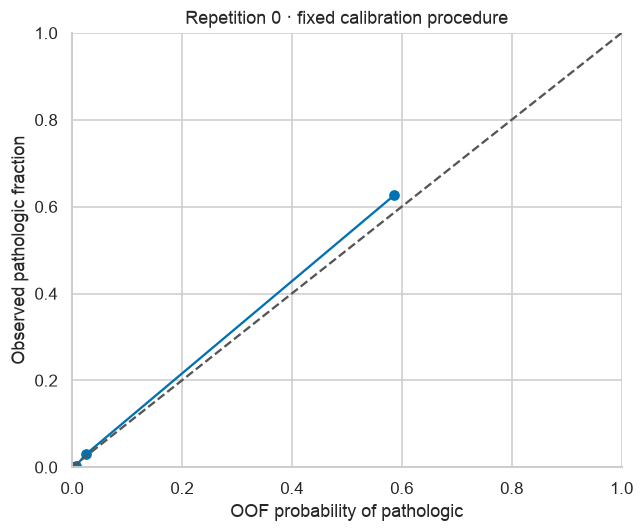

In [7]:
from src.training.ctg_review_models import weights
pred=pd.read_parquet(UCI/'nested_predictions.parquet')
g=pred[(pred.repetition==0)&(pred.family=='selected_procedure')].copy()
g['_weight']=weights(g.review_group);g['bin']=pd.qcut(g.p2,8,duplicates='drop');rows=[]
for label,z in g.groupby('bin',observed=True):
    w=z['_weight'].to_numpy();rows.append(dict(p=np.average(z.p2,weights=w),observed=np.average(z.NSP==3,weights=w),segments=len(z),groups=z.review_group.nunique()))
bins=pd.DataFrame(rows);display(bins.round(4))
fig,ax=plt.subplots(figsize=(6,5));ax.plot(bins.p,bins.observed,'o-',color='#0072b2');ax.plot([0,1],[0,1],'--',color='#555555')
ax.set(xlabel='OOF probability of pathologic',ylabel='Observed pathologic fraction',xlim=(0,1),ylim=(0,1),title='Repetition 0 · fixed calibration procedure')
fig.tight_layout();save_show('uci03_oof_calibration.png')
print('Bundles:',len(list(export.glob('*.joblib'))),'native CatBoost:',len(list(export.glob('*.cbm'))))
print('Полный logistic preprocessor сохранён отдельно; после fit на всей UCI независимого test для этого файла нет.')


## Takeaways

UCI используется как benchmark экспертных классов. Префикс — прокси независимого источника, не подтверждённый ID пациентки. Все данные ранее просмотрены: эта ревизия оценивает исправленную процедуру на повторной nested CV, без нового blind-test заявления. Полный разбор 23 замечаний — в [07](07_deep_audit_and_recommendations.ipynb).
